In [1]:
import pandas as pd
from pathlib import Path

In [2]:
driver_train = pd.read_csv("../data/splits/driver_based/train.csv")
driver_val = pd.read_csv("../data/splits/driver_based/val.csv")
driver_test = pd.read_csv("../data/splits/driver_based/test.csv")

print("Train:", driver_train.shape)
print("Val:", driver_val.shape)
print("Test:", driver_test.shape)

Train: (15732, 4)
Val: (3603, 4)
Test: (3089, 4)


## Step 1 — Locate Image Files
Find the original images and create their full file paths.

In [3]:
# Find the folder containing the original images
sample_img = driver_train.iloc[0]["img"]
sample_path = next(Path("../data").rglob(sample_img))

image_root = sample_path.parent.parent

# Add full image paths to training and validation data
for data in [driver_train, driver_val]:
    data["filepath"] = data.apply(
        lambda row: str(
            image_root / row["classname"] / row["img"]
        ),
        axis=1
    )

# Verify the first image exists
print("Image root:", image_root)
print("First image exists:", Path(driver_train.iloc[0]["filepath"]).is_file())

driver_train.head()

Image root: ../data/raw/state-farm-distracted-driver-detection/imgs/train
First image exists: True


,subject,classname,img,split,filepath
0,p002,c0,img_44733.jpg,train,../data/raw/state-farm-distracted-driver-detec...
1,p002,c0,img_72999.jpg,train,../data/raw/state-farm-distracted-driver-detec...
2,p002,c0,img_25094.jpg,train,../data/raw/state-farm-distracted-driver-detec...
3,p002,c0,img_69092.jpg,train,../data/raw/state-farm-distracted-driver-detec...
4,p002,c0,img_92629.jpg,train,../data/raw/state-farm-distracted-driver-detec...


## Step 2 — Image Preprocessing and HOG Feature Extraction
Convert images to grayscale, resize them to 64×64,
and extract HOG features for classification.

In [4]:
from skimage.io import imread
from skimage.color import rgb2gray
from skimage.transform import resize
from skimage.feature import hog

# Load one training image
image = imread(driver_train.iloc[0]["filepath"])

# Convert to grayscale
gray = rgb2gray(image)

# Resize to 64x64 pixels
gray = resize(gray, (64, 64), anti_aliasing=True)

# Extract HOG features
features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

print("Image shape:", gray.shape)
print("HOG features:", features.shape)

Image shape: (64, 64)
HOG features: (1764,)


## Step 3 — Visualize HOG Features

Compare the original driver image with its HOG feature visualization.

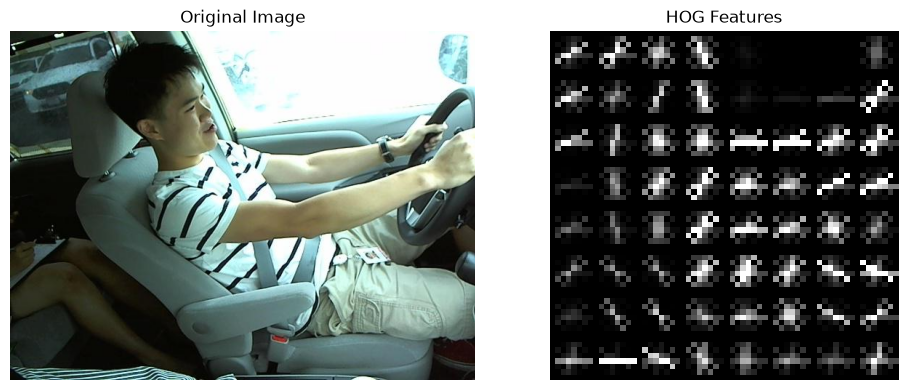

In [5]:
import matplotlib.pyplot as plt
from skimage import exposure

# Improve visibility of HOG edges
hog_display = exposure.rescale_intensity(
    hog_image, in_range=(0, 0.1)
)

# Display original image and HOG visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(hog_display, cmap="gray")
axes[1].set_title("HOG Features")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Step 4 — Extract HOG Features from Training Data

Convert each image into a fixed-length feature vector for SVM training.

In [6]:
def extract_hog(image_path):
    # Load image
    image = imread(image_path)

    # Convert to grayscale and resize
    gray = rgb2gray(image)
    gray = resize(gray, (64, 64), anti_aliasing=True)

    # Extract numerical HOG features
    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2)
    )

    return features

# Test on one image
sample_features = extract_hog(driver_train.iloc[0]["filepath"])

print("Feature vector shape:", sample_features.shape)

Feature vector shape: (1764,)


## Step 5 — Build HOG Feature Dataset

Extract HOG features from all training and validation images.

In [ ]:
import numpy as np
from tqdm.auto import tqdm

def build_features(data):
    # Extract HOG features from each image
    X = np.array([
        extract_hog(path)
        for path in tqdm(data["filepath"])
    ])

    # Extract class labels
    y = data["classname"].to_numpy(dtype="U10")

    return X, y


# Build training features
X_train, y_train = build_features(driver_train)

# Build validation features
X_val, y_val = build_features(driver_val)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

  0%|          | 0/15732 [00:00<?, ?it/s]

  0%|          | 0/3603 [00:00<?, ?it/s]

Training: (15732, 1764)
Validation: (3603, 1764)


## Step 6 — Save HOG Features
Save training and validation features as NumPy files for reuse.


In [11]:
from pathlib import Path
import numpy as np

# Create folder for extracted features
feature_dir = Path("../data/processed/hog/driver_based")
feature_dir.mkdir(parents=True, exist_ok=True)

# Save features
np.save(feature_dir / "X_train.npy", X_train)
np.save(feature_dir / "X_val.npy", X_val)

# Save corresponding class labels
np.save(feature_dir / "y_train.npy", y_train.astype("U10"))
np.save(feature_dir / "y_val.npy", y_val.astype("U10"))
print("HOG features and labels saved successfully!")

HOG features and labels saved successfully!


## Step 7 — Train HOG + SVM Baseline

Use StandardScaler and LinearSVC to train a classical
image classification model.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
import numpy as np

# Load saved HOG features and labels
feature_dir = Path("../data/processed/hog/driver_based")

X_train = np.load(feature_dir / "X_train.npy")
y_train = np.load(feature_dir / "y_train.npy")

X_val = np.load(feature_dir / "X_val.npy")
y_val = np.load(feature_dir / "y_val.npy")

# Create scaling + classification pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        C=1.0,
        max_iter=10000,
        random_state=42
    ))
])

# Train the model
pipeline.fit(X_train, y_train)

print("SVM training completed!")

SVM training completed!


In [13]:
import joblib
from pathlib import Path

# Create a folder for trained models
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the entire fitted pipeline
joblib.dump(
    pipeline,
    model_dir / "hog_svm_driver_based.joblib"
)

print("Trained model saved successfully!")

Trained model saved successfully!


In [14]:
svm = pipeline.named_steps["svm"]

print("Weights:", svm.coef_.shape)
print("Biases:", svm.intercept_.shape)

total_params = svm.coef_.size + svm.intercept_.size
print("Total SVM parameters:", total_params)

Weights: (10, 1764)
Biases: (10,)
Total SVM parameters: 17650


## Step 9 — Evaluate HOG + SVM on Validation Data

Measure accuracy, macro-F1, precision, and recall on unseen drivers.

In [15]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Predict validation labels
y_pred = pipeline.predict(X_val)

# Calculate evaluation metrics
accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average="macro")

print(f"Validation Accuracy: {accuracy:.2%}")
print(f"Validation Macro-F1: {macro_f1:.4f}")

# Show precision, recall, and F1 for each class
print("\nClassification Report:")
print(classification_report(y_val, y_pred, zero_division=0))

Validation Accuracy: 42.52%
Validation Macro-F1: 0.4180

Classification Report:
              precision    recall  f1-score   support

          c0       0.19      0.39      0.26       372
          c1       0.63      0.33      0.43       377
          c2       0.73      0.28      0.40       367
          c3       0.43      0.26      0.33       393
          c4       0.81      0.47      0.59       378
          c5       0.47      0.90      0.62       372
          c6       0.85      0.43      0.57       372
          c7       0.38      0.81      0.52       342
          c8       0.65      0.24      0.36       298
          c9       0.10      0.10      0.10       332

    accuracy                           0.43      3603
   macro avg       0.52      0.42      0.42      3603
weighted avg       0.53      0.43      0.42      3603



## Step 10 — Confusion Matrix

Visualize which driving activities the HOG + SVM
model classifies correctly and incorrectly.

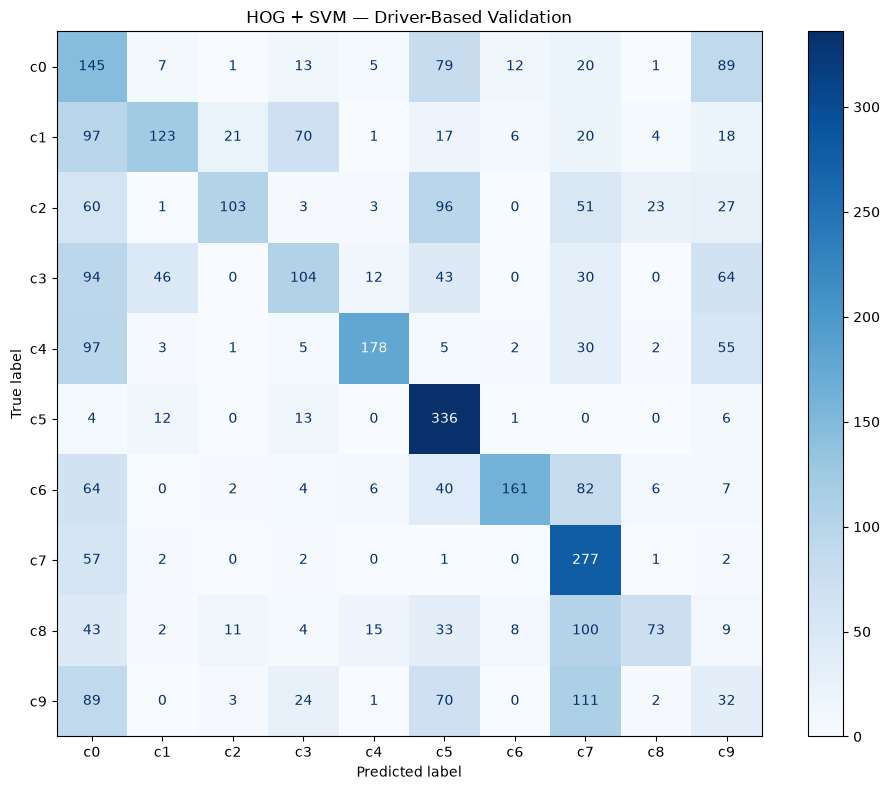

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Display confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    labels=[f"c{i}" for i in range(10)],
    cmap="Blues",
    ax=ax
)

plt.title("HOG + SVM — Driver-Based Validation")
plt.tight_layout()
plt.show()

## Experiment 1 — HOG + Linear SVM

- Split protocol: Driver-based (18/4/4 drivers)
- HOG features: 1,764 per image
- Training samples: 15,732
- Validation samples: 3,603
- SVM: LinearSVC, C=1.0, max_iter=10000
- Random seed: 42
- Training time: 24 minutes 37 seconds (observed notebook runtime)
- Validation accuracy: 42.52%
- Validation macro-F1: 0.4180
- Hardware: Mac CPU